# Language Identification — Fixed & Stabilized Pipeline

نسخة مصححة من الـ pipeline بتاع `papluca/language-identification`.

**المشكلة الأصلية:** عدم استقرار الدقة بين تشغيلة وتانية (أحياناً ممتازة، أحياناً منهارة تماماً).

**السبب الجذري:** الـ padding tokens كانت بتتغذى في طبقات LSTM/GRU من غير masking، فبعد آلاف الخطوات المتكررة من نفس قيمة الـ PAD كان الـ hidden state بيتصرف بشكل غير مستقر حسب الـ random seed (نفس فكرة power iteration على مصفوفة عشوائية).

**الإصلاحات:**
- Masking فعلي جوه الـ LSTM/GRU عبر `mask=` مع `keras.ops.cast` (متوافق مع Keras 3)
- تثبيت كل الـ random seeds (numpy, python, tf)
- `clipnorm=1.0` على كل الموديلات مش موديل واحد بس
- `maxlen` محسوب من الـ percentile 95 للبيانات الفعلية بدل رقم ثابت
- `vocab_size = len(tokenizer)` بدل `tokenizer.vocab_size` (تغطية ديناميكية لأي tokenizer)

In [1]:
import random
from typing import Sequence

import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from datasets import load_dataset
from transformers import AutoTokenizer, PreTrainedTokenizerBase
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from keras.preprocessing.sequence import pad_sequences

## 1. تثبيت الـ Seeds
مهم جداً عشان نقدر نقارن النتائج بين التجارب ونتأكد إن أي تحسّن حقيقي مش مجرد seed كويس.

In [2]:
SEED = 42

def set_seeds(seed: int = SEED) -> None:
    """Fix every source of randomness so runs are reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds()

## 2. تحميل وتنظيف البيانات

In [3]:
def load_and_clean_data() -> pd.DataFrame:
    """Load all three HF splits, dedupe, and map label codes to language names."""
    ds = load_dataset("papluca/language-identification")
    df = pd.concat(
        [ds["train"].to_pandas(), ds["validation"].to_pandas(), ds["test"].to_pandas()],
        ignore_index=True,
    )
    df = df.drop_duplicates(subset=["text", "labels"]).copy()

    lang_mapping = {
        "ar": "Arabic", "bg": "Bulgarian", "de": "German", "el": "Greek",
        "en": "English", "es": "Spanish", "fr": "French", "hi": "Hindi",
        "it": "Italian", "ja": "Japanese", "nl": "Dutch", "pl": "Polish",
        "pt": "Portuguese", "ru": "Russian", "th": "Thai", "tr": "Turkish",
        "ur": "Urdu", "vi": "Vietnamese", "zh": "Chinese", "sw": "Swahili",
    }
    df["labels"] = df["labels"].map(lang_mapping)
    df.rename(columns={"labels": "languages"}, inplace=True)
    df["text"] = df["text"].str.strip()
    return df

df = load_and_clean_data()
df.head()

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/12.0M [00:00<?, ?B/s]

valid.csv:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.69M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/70000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

,languages,text
0,Portuguese,"os chefes de defesa da estónia, letónia, lituâ..."
1,Bulgarian,размерът на хоризонталната мрежа може да бъде ...
2,Chinese,很好，以前从不去评价，不知道浪费了多少积分，现在知道积分可以换钱，就要好好评价了，后来我就把...
3,Thai,สำหรับ ของเก่า ที่ จริงจัง ลอง honeychurch ...
4,Russian,Он увеличил давление .


## 3. تحميل الـ Tokenizer وحساب الـ vocab size ديناميكياً

In [4]:
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

# len(tokenizer) بدل tokenizer.vocab_size: بيحسب كل الـ ids اللي ممكن
# الـ tokenizer يطلعها فعلاً (بما فيها special/added tokens)، مش بس الـ base vocab.
vocab_size = len(tokenizer)
print(f"Vocab size: {vocab_size}")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Vocab size: 250002


## 4. Tokenize + Padding (maxlen محسوب من البيانات نفسها)

In [5]:
def tokenize_and_pad(
    df: pd.DataFrame, tokenizer: PreTrainedTokenizerBase, percentile: float = 95.0
) -> tuple[np.ndarray, np.ndarray, int]:
    """Tokenize, pick maxlen from the data (not a guessed constant), and pad."""
    token_lists: Sequence[list[int]] = df["text"].apply(
        lambda t: tokenizer.encode(t, add_special_tokens=True)
    )
    lengths = token_lists.apply(len)
    maxlen = int(np.percentile(lengths, percentile))
    print(f"Chosen maxlen (p{percentile}): {maxlen}  |  raw max: {lengths.max()}")

    pad_id = tokenizer.pad_token_id
    X = pad_sequences(token_lists, maxlen=maxlen, padding="post", truncating="post", value=pad_id)
    attention_mask = (X != pad_id).astype("int32")
    return X, attention_mask, maxlen

X, attention_mask, maxlen = tokenize_and_pad(df, tokenizer)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (556 > 512). Running this sequence through the model will result in indexing errors


Chosen maxlen (p95.0): 84  |  raw max: 864


## 5. ترميز الـ Labels والتقسيم Stratified

In [6]:
le = LabelEncoder()
y = le.fit_transform(df["languages"])
num_classes = len(le.classes_)

X_train, X_test, mask_train, mask_test, y_train, y_test = train_test_split(
    X, attention_mask, y, test_size=0.2, random_state=SEED, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("num_classes  :", num_classes)

X_train shape: (69624, 84)
X_test shape : (17406, 84)
num_classes  : 20


## 6. Callbacks

In [7]:
def get_callbacks() -> list[tf.keras.callbacks.Callback]:
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=4, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
        ),
    ]

## 7. الموديل — LSTM/GRU مع Masking فعلي

دي أهم خطوة: بنمرر `mask=bool_mask` لكل طبقة recurrent صراحة، عشان الـ PAD steps ما تأثرش على الـ hidden state.

**مهم:** بنستخدم `keras.ops.cast` مش `tf.cast` — لأن Keras 3 بيرفض تطبيق TF ops خام على `KerasTensor` جوه الـ Functional API.

In [8]:
def build_masked_rnn_model(
    vocab_size: int,
    num_classes: int,
    maxlen: int,
    cell: str = "lstm",
    embed_dim: int = 64,
) -> tf.keras.Model:
    """
    Stacked recurrent classifier that actually respects the attention mask.

    The mask is threaded through both recurrent layers via the `mask=`
    kwarg, so PAD timesteps never update the recurrent state.
    """
    rnn_layer = tf.keras.layers.LSTM if cell == "lstm" else tf.keras.layers.GRU

    input_ids = tf.keras.Input(shape=(maxlen,), dtype=tf.int32, name="input_ids")
    attn_mask_in = tf.keras.Input(shape=(maxlen,), dtype=tf.int32, name="attention_mask")
    # keras.ops.cast (NOT tf.cast) — required under Keras 3 Functional API
    bool_mask = keras.ops.cast(attn_mask_in, "bool")

    x = tf.keras.layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)(input_ids)
    x = tf.keras.layers.SpatialDropout1D(0.2)(x)
    x = rnn_layer(128, return_sequences=True)(x, mask=bool_mask)
    x = rnn_layer(64)(x, mask=bool_mask)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(
        inputs=[input_ids, attn_mask_in], outputs=outputs, name=f"{cell.upper()}_Model_Masked"
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_masked_rnn_model(vocab_size, num_classes, maxlen, cell="lstm")
model.summary()

Model: "LSTM_Model_Masked"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 84)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 84, 64)    │ 16,000,128 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_mask      │ (None, 84)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 84, 64)    │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast (Cast)         │ (None, 84)        │          0 │ attention_mask[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 84, 128)   │     98,816 │ spatial_dropout1… │
│                     │                   │            │ cast[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64)        │     49,408 │ lstm[0][0],       │
│                     │                   │            │ cast[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 20)        │      1,300 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 16,153,812 (61.62 MB)

 Trainable params: 16,153,812 (61.62 MB)

 Non-trainable params: 0 (0.00 B)

## 8. التدريب

In [9]:
history = model.fit(
    x={"input_ids": X_train, "attention_mask": mask_train},
    y=y_train,
    epochs=25,
    batch_size=64,
    validation_split=0.2,
    callbacks=get_callbacks(),
)

Epoch 1/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 31s 26ms/step - accuracy: 0.8338 - loss: 0.5540 - val_accuracy: 0.9764 - val_loss: 0.0890 - learning_rate: 0.0010
Epoch 2/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9815 - loss: 0.0737 - val_accuracy: 0.9836 - val_loss: 0.0617 - learning_rate: 0.0010
Epoch 3/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 36s 41ms/step - accuracy: 0.9907 - loss: 0.0391 - val_accuracy: 0.9838 - val_loss: 0.0678 - learning_rate: 0.0010
Epoch 4/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 35s 41ms/step - accuracy: 0.9945 - loss: 0.0264 - val_accuracy: 0.9818 - val_loss: 0.0786 - learning_rate: 0.0010
Epoch 5/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 29s 27ms/step - accuracy: 0.9977 - loss: 0.0116 - val_accuracy: 0.9859 - val_loss: 0.0657 - learning_rate: 3.0000e-04
Epoch 6/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.9986 - loss: 0.0071 - val_accuracy: 0.9870 - val_loss: 0.0632 - learning_rate: 3.0000e-04
Epoch 7/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.

## 9. التقييم على الـ Test Set

In [10]:
test_loss, test_acc = model.evaluate(
    x={"input_ids": X_test, "attention_mask": mask_test}, y=y_test
)
print(f"Test accuracy: {test_acc:.4f}")

544/544 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9884 - loss: 0.0617
Test accuracy: 0.9884


## 10. (اختياري) Classification Report + Confusion Matrix

544/544 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
              precision    recall  f1-score   support

      Arabic       0.99      1.00      0.99       861
   Bulgarian       0.98      0.99      0.99       861
     Chinese       1.00      1.00      1.00       898
       Dutch       0.98      0.98      0.98       850
     English       0.99      0.99      0.99       900
      French       1.00      0.99      0.99       898
      German       0.99      1.00      0.99       900
       Greek       0.99      1.00      0.99       861
       Hindi       1.00      0.99      1.00       861
     Italian       0.98      0.99      0.98       852
    Japanese       1.00      1.00      1.00       900
      Polish       0.98      0.99      0.99       848
  Portuguese       0.98      0.99      0.98       853
     Russian       0.98      0.98      0.98       861
     Spanish       0.99      0.98      0.98       899
     Swahili       0.96      0.98      0.97       861
        Thai       1.00      1.00      1

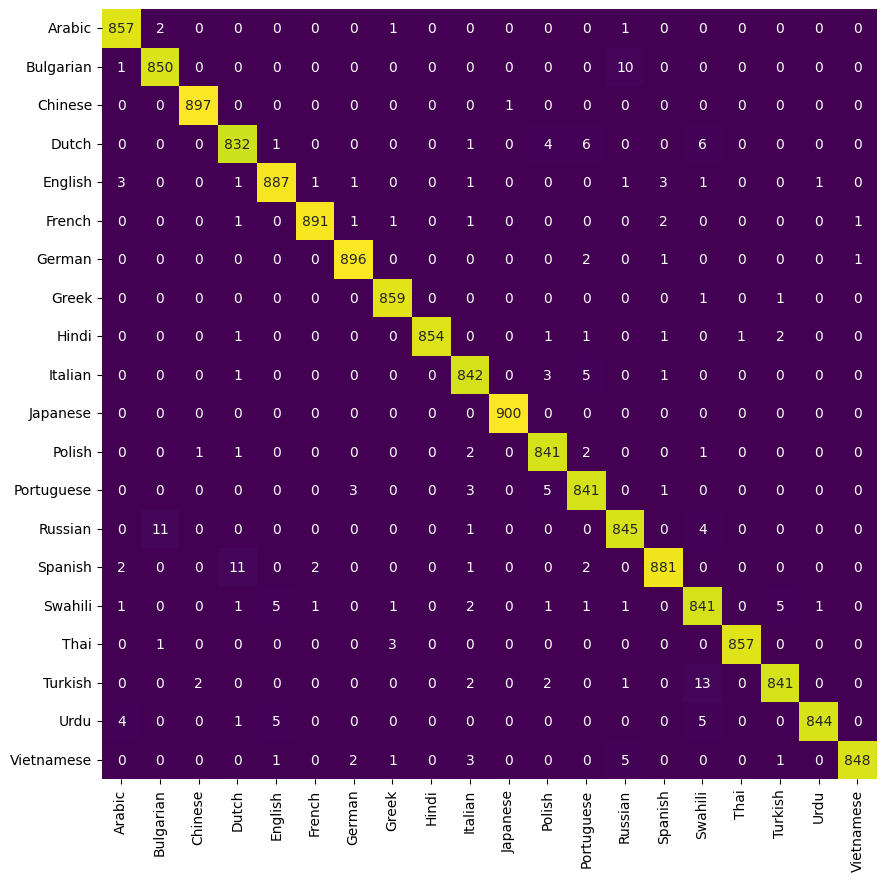

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = model.predict(
    {"input_ids": X_test, "attention_mask": mask_test}
).argmax(axis=-1)

class_names = le.classes_
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt="g", cmap="viridis",
            xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xticks(rotation=90)
plt.show()

## 11. (اختياري) نفس الموديل بـ GRU
لاحظ إن نفس الـ masking fix لازم يتطبق هنا كمان — الكود عندك الأصلي كان ناقصه.

In [12]:
gru_model = build_masked_rnn_model(vocab_size, num_classes, maxlen, cell="gru")
gru_model.summary()

gru_history = gru_model.fit(
    x={"input_ids": X_train, "attention_mask": mask_train},
    y=y_train,
    epochs=25,
    batch_size=64,
    validation_split=0.2,
    callbacks=get_callbacks(),
)

Model: "GRU_Model_Masked"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 84)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 84, 64)    │ 16,000,128 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_mask      │ (None, 84)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_1 │ (None, 84, 64)    │          0 │ embedding_1[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast_1 (Cast)       │ (None, 84)        │          0 │ attention_mask[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 84, 128)   │     74,496 │ spatial_dropout1… │
│                     │                   │            │ cast_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 64)        │     37,248 │ gru[0][0],        │
│                     │                   │            │ cast_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      4,160 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 20)        │      1,300 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 16,117,332 (61.48 MB)

 Trainable params: 16,117,332 (61.48 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 24s 25ms/step - accuracy: 0.7903 - loss: 0.6598 - val_accuracy: 0.9744 - val_loss: 0.0990 - learning_rate: 0.0010
Epoch 2/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9806 - loss: 0.0836 - val_accuracy: 0.9821 - val_loss: 0.0696 - learning_rate: 0.0010
Epoch 3/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9909 - loss: 0.0396 - val_accuracy: 0.9850 - val_loss: 0.0697 - learning_rate: 0.0010
Epoch 4/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9945 - loss: 0.0260 - val_accuracy: 0.9827 - val_loss: 0.0834 - learning_rate: 0.0010
Epoch 5/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 41s 24ms/step - accuracy: 0.9980 - loss: 0.0109 - val_accuracy: 0.9887 - val_loss: 0.0675 - learning_rate: 3.0000e-04
Epoch 6/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9991 - loss: 0.0061 - val_accuracy: 0.9879 - val_loss: 0.0700 - learning_rate: 3.0000e-04
Epoch 7/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.

## 12. موديل Transformer from scratch

نفس الفكرة اللي كانت في notebook الأصلي بتاعك، لكن بـ `vocab_size` و `maxlen` المحسوبين ديناميكياً، ومع إضافة `clipnorm=1.0` (كان ناقص في الأصلي).

ملحوظة: هنا الـ `attention_mask` بيتستخدم جوه الـ `MultiHeadAttention` مباشرة، فمفيش مشكلة الـ padding اللي كانت في LSTM/GRU.

In [13]:
from tensorflow.keras import layers


class TransformerBlock(layers.Layer):
    """Standard pre-LN-style Transformer encoder block (post-LN here, matches original)."""

    def __init__(self, embed_dim: int, num_heads: int, ff_dim: int, rate: float = 0.1, **kwargs):
        super().__init__(**kwargs)
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim),
        ])
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)

    def call(self, inputs, training: bool = False, attention_mask=None):
        attn_output = self.att(inputs, inputs, attention_mask=attention_mask)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)


class PositionalEmbedding(layers.Layer):
    """Token embedding + learned positional embedding."""

    def __init__(self, maxlen: int, vocab_size: int, embed_dim: int, **kwargs):
        super().__init__(**kwargs)
        self.token_emb = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = layers.Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        return self.token_emb(x) + positions

In [14]:
def build_transformer_model(
    vocab_size: int,
    num_classes: int,
    maxlen: int,
    embed_dim: int = 64,
    num_heads: int = 4,
    ff_dim: int = 128,
    num_blocks: int = 2,
) -> tf.keras.Model:
    """From-scratch Transformer encoder classifier with a proper attention mask."""
    token_input = layers.Input(shape=(maxlen,), dtype=tf.int32, name="input_ids")
    mask_input = layers.Input(shape=(maxlen,), dtype=tf.int32, name="attention_mask")

    x = PositionalEmbedding(maxlen, vocab_size, embed_dim)(token_input)

    attn_mask = keras.ops.cast(mask_input, "bool")
    attn_mask = keras.ops.expand_dims(attn_mask, axis=1)

    for _ in range(num_blocks):
        x = TransformerBlock(embed_dim, num_heads, ff_dim)(x, attention_mask=attn_mask)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(
        inputs=[token_input, mask_input], outputs=outputs, name="Transformer_Scratch"
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),  # clipping added (was missing originally)
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


transformer_model = build_transformer_model(vocab_size, num_classes, maxlen)
transformer_model.summary()

Model: "Transformer_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ attention_mask      │ (None, 84)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_ids           │ (None, 84)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast_2 (Cast)       │ (None, 84)        │          0 │ attention_mask[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 84, 64)    │ 16,005,504 │ input_ids[0][0]   │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expand_dims         │ (None, 1, 84)     │          0 │ cast_2[0][0]      │
│ (ExpandDims)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block   │ (None, 84, 64)    │     83,200 │ positional_embed… │
│ (TransformerBlock)  │                   │            │ expand_dims[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_1 │ (None, 84, 64)    │     83,200 │ transformer_bloc… │
│ (TransformerBlock)  │                   │            │ expand_dims[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ transformer_bloc… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │      4,160 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 64)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 20)        │      1,300 │ dropout_9[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 16,177,364 (61.71 MB)

 Trainable params: 16,177,364 (61.71 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
transformer_history = transformer_model.fit(
    x={"input_ids": X_train, "attention_mask": mask_train},
    y=y_train,
    epochs=25,
    batch_size=64,
    validation_split=0.2,
    callbacks=get_callbacks(),
)

Epoch 1/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 40s 27ms/step - accuracy: 0.8956 - loss: 0.3830 - val_accuracy: 0.9854 - val_loss: 0.0625 - learning_rate: 0.0010
Epoch 2/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9889 - loss: 0.0501 - val_accuracy: 0.9878 - val_loss: 0.0586 - learning_rate: 0.0010
Epoch 3/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9948 - loss: 0.0218 - val_accuracy: 0.9891 - val_loss: 0.0645 - learning_rate: 0.0010
Epoch 4/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9963 - loss: 0.0152 - val_accuracy: 0.9873 - val_loss: 0.0860 - learning_rate: 0.0010
Epoch 5/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9990 - loss: 0.0049 - val_accuracy: 0.9905 - val_loss: 0.0703 - learning_rate: 3.0000e-04
Epoch 6/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9996 - loss: 0.0020 - val_accuracy: 0.9906 - val_loss: 0.0761 - learning_rate: 3.0000e-04
Epoch 7/25
871/871 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.

## 13. مقارنة شاملة بين الموديلات التلاتة (LSTM / GRU / Transformer)

جدول واحد بيقارن accuracy, loss, وعدد الـ epochs اللي وقف عندها كل موديل (بفضل الـ EarlyStopping)، بالإضافة لـ classification report لكل واحد.

In [16]:
def evaluate_model(model: tf.keras.Model, name: str) -> dict:
    """Evaluate a model on the held-out test set and return a summary dict."""
    loss, acc = model.evaluate(
        x={"input_ids": X_test, "attention_mask": mask_test}, y=y_test, verbose=0
    )
    return {"model": name, "test_loss": loss, "test_accuracy": acc}


results = [
    evaluate_model(model, "LSTM (masked)"),
    evaluate_model(gru_model, "GRU (masked)"),
    evaluate_model(transformer_model, "Transformer (scratch)"),
]

results_df = pd.DataFrame(results).sort_values("test_accuracy", ascending=False)
results_df

,model,test_loss,test_accuracy
2,Transformer (scratch),0.075582,0.991038
1,GRU (masked),0.062515,0.989831
0,LSTM (masked),0.061743,0.988395


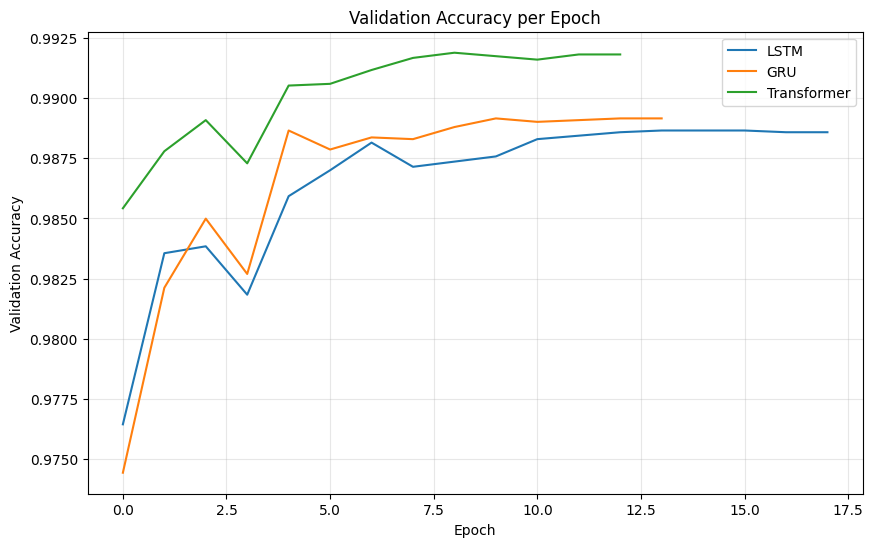

In [17]:
def plot_comparison(histories: dict[str, tf.keras.callbacks.History]) -> None:
    """Plot validation accuracy curves for all models on one chart."""
    plt.figure(figsize=(10, 6))
    for name, hist in histories.items():
        plt.plot(hist.history["val_accuracy"], label=name)
    plt.title("Validation Accuracy per Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Validation Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


plot_comparison({
    "LSTM": history,
    "GRU": gru_history,
    "Transformer": transformer_history,
})

## 14. Testing بجمل جديدة (Inference)

دالة واحدة بتاخد أي موديل + جملة نص وتطلعلك اللغة المتوقعة، وممكن كمان تقارن الموديلات التلاتة على نفس الجملة.

In [18]:
def predict_language(
    text: str,
    model: tf.keras.Model,
    tokenizer: PreTrainedTokenizerBase,
    label_encoder: LabelEncoder,
    maxlen: int,
    needs_mask_input: bool = True,
) -> tuple[str, float]:
    """Run a single raw sentence through the full preprocessing + model pipeline."""
    tokens = tokenizer.encode(text.strip(), add_special_tokens=True)
    pad_id = tokenizer.pad_token_id
    padded = pad_sequences(
        [tokens], maxlen=maxlen, padding="post", truncating="post", value=pad_id
    )
    mask = (padded != pad_id).astype("int32")

    if needs_mask_input:
        probs = model.predict(
            {"input_ids": padded, "attention_mask": mask}, verbose=0
        )[0]
    else:
        probs = model.predict(padded, verbose=0)[0]

    predicted_id = int(np.argmax(probs))
    predicted_label = label_encoder.inverse_transform([predicted_id])[0]
    confidence = float(probs[predicted_id])
    return predicted_label, confidence


test_sentences = [
    "The weather is absolutely beautiful today.",          # English
    "أعتقد أن هذا المشروع سيكون ناجحاً جداً.",              # Arabic
    "Je pense que ce projet sera un grand succès.",         # French
    "Das ist ein wirklich interessantes Projekt.",          # German
    "Este proyecto va a ser un gran éxito.",                # Spanish
    "Questo progetto sarà un grande successo.",             # Italian
    "この プロジェクトは 成功するでしょう。",                    # Japanese
    "这个项目将会非常成功。",                                  # Chinese
    "यह परियोजना बहुत सफल होगी।",                            # Hindi
    "Bu proje çok başarılı olacak.",                        # Turkish
]

for sentence in test_sentences:
    lstm_pred, lstm_conf = predict_language(sentence, model, tokenizer, le, maxlen)
    gru_pred, gru_conf = predict_language(sentence, gru_model, tokenizer, le, maxlen)
    trans_pred, trans_conf = predict_language(sentence, transformer_model, tokenizer, le, maxlen)

    print(f"Sentence: {sentence}")
    print(f"  LSTM        -> {lstm_pred:12s} ({lstm_conf:.2%})")
    print(f"  GRU         -> {gru_pred:12s} ({gru_conf:.2%})")
    print(f"  Transformer -> {trans_pred:12s} ({trans_conf:.2%})")
    print("-" * 60)

Sentence: The weather is absolutely beautiful today.
  LSTM        -> English      (100.00%)
  GRU         -> English      (99.87%)
  Transformer -> English      (100.00%)
------------------------------------------------------------
Sentence: أعتقد أن هذا المشروع سيكون ناجحاً جداً.
  LSTM        -> Arabic       (100.00%)
  GRU         -> Arabic       (100.00%)
  Transformer -> Arabic       (100.00%)
------------------------------------------------------------
Sentence: Je pense que ce projet sera un grand succès.
  LSTM        -> French       (100.00%)
  GRU         -> French       (99.97%)
  Transformer -> Spanish      (100.00%)
------------------------------------------------------------
Sentence: Das ist ein wirklich interessantes Projekt.
  LSTM        -> German       (100.00%)
  GRU         -> German       (100.00%)
  Transformer -> German       (100.00%)
------------------------------------------------------------
Sentence: Este proyecto va a ser un gran éxito.
  LSTM        -> S

### جدول مقارنة منظم (كل جملة + توقع كل موديل)
لو عايز شكل جدول واضح بدل الطباعة النصية فوق.

In [19]:
comparison_rows = []
for sentence in test_sentences:
    lstm_pred, lstm_conf = predict_language(sentence, model, tokenizer, le, maxlen)
    gru_pred, gru_conf = predict_language(sentence, gru_model, tokenizer, le, maxlen)
    trans_pred, trans_conf = predict_language(sentence, transformer_model, tokenizer, le, maxlen)
    comparison_rows.append({
        "sentence": sentence,
        "LSTM_pred": lstm_pred, "LSTM_conf": round(lstm_conf, 3),
        "GRU_pred": gru_pred, "GRU_conf": round(gru_conf, 3),
        "Transformer_pred": trans_pred, "Transformer_conf": round(trans_conf, 3),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,sentence,LSTM_pred,LSTM_conf,GRU_pred,GRU_conf,Transformer_pred,Transformer_conf
0,The weather is absolutely beautiful today.,English,1.000,English,0.999,English,1.0
1,أعتقد أن هذا المشروع سيكون ناجحاً جداً.,Arabic,1.000,Arabic,1.000,Arabic,1.0
2,Je pense que ce projet sera un grand succès.,French,1.000,French,1.000,Spanish,1.0
3,Das ist ein wirklich interessantes Projekt.,German,1.000,German,1.000,German,1.0
4,Este proyecto va a ser un gran éxito.,Spanish,0.994,Spanish,0.979,Spanish,1.0
5,Questo progetto sarà un grande successo.,Italian,0.992,Italian,1.000,Italian,1.0
6,この プロジェクトは 成功するでしょう。,Japanese,1.000,Japanese,1.000,Japanese,1.0
7,这个项目将会非常成功。,Chinese,1.000,Chinese,1.000,Chinese,1.0
8,यह परियोजना बहुत सफल होगी।,Hindi,1.000,Hindi,1.000,Hindi,1.0
9,Bu proje çok başarılı olacak.,Turkish,1.000,Turkish,1.000,Turkish,1.0
